In [62]:
import pandas as pd
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from google.colab import files
import os
import matplotlib.pyplot as plt


In [ ]:
uploaded = files.upload()
print(os.getcwd())
print(os.listdir())

In [63]:
# dataframe
cs = pd.read_csv('customer.csv')
print(cs.head())
print(cs.shape)
print(cs.info())
print(cs.columns)
print(cs.isnull().sum())
print(cs.describe())


   Age  Gender   AnnualIncome  ...  LoyaltyProgram  DiscountsAvailed  PurchaseStatus
0   40       1   66120.267939  ...               0                 5               1
1   20       1   23579.773583  ...               0                 5               0
2   27       1  127821.306432  ...               1                 0               1
3   24       1  137798.623120  ...               0                 4               1
4   31       1   99300.964220  ...               0                 0               1

[5 rows x 9 columns]
(1500, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 1500 non-null   int64  
 1   Gender              1500 non-null   int64  
 2   AnnualIncome        1500 non-null   float64
 3   NumberOfPurchases   1500 non-null   int64  
 4   ProductCategory     1500 non-null   int64  
 5   Time

In [64]:
# feature selection
X = cs.drop(columns=['PurchaseStatus'])
y = cs['PurchaseStatus']
print(X.head())
print(y.head())
print('x shape:',X.shape)
print('y shape ;', y.shape)

   Age  Gender  ...  LoyaltyProgram  DiscountsAvailed
0   40       1  ...               0                 5
1   20       1  ...               0                 5
2   27       1  ...               1                 0
3   24       1  ...               0                 4
4   31       1  ...               0                 0

[5 rows x 8 columns]
0    1
1    0
2    1
3    1
4    1
Name: PurchaseStatus, dtype: int64
x shape: (1500, 8)
y shape ; (1500,)


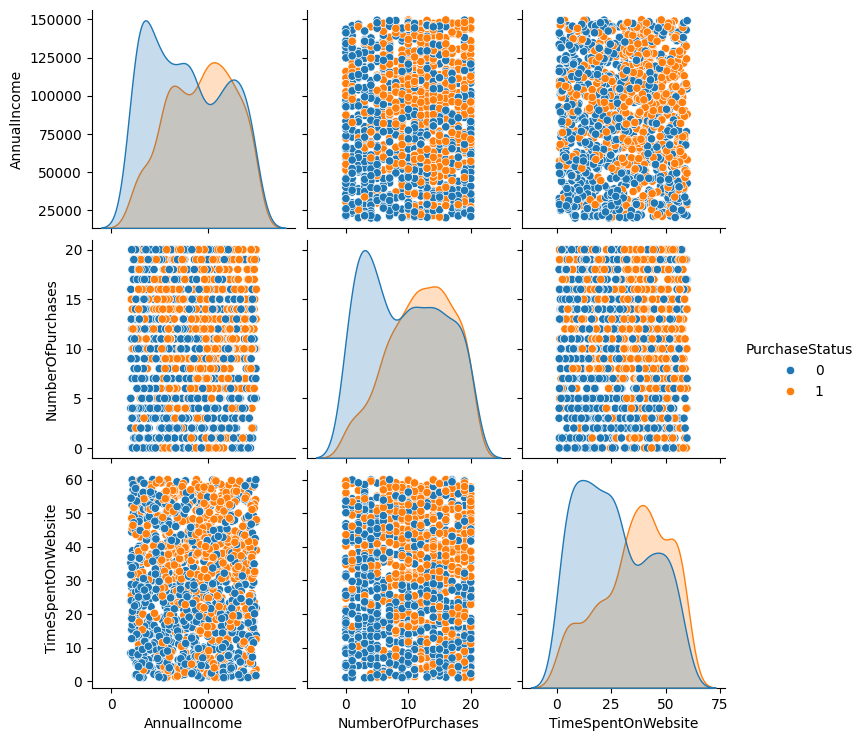

In [65]:
#EDA
sns.pairplot(
    cs,
    vars=['AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite'],
    hue='PurchaseStatus'
)

plt.show()

In [66]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (1200, 8)
X_test: (300, 8)
y_train: (1200,)
y_test: (300,)


In [67]:

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)

)
# model train
model.fit(X_train,y_train)
#predict
y_pred = model.predict(X_test)
print("Predicted Values:")
print(y_pred)

Predicted Values:
[0 0 1 1 0 1 0 1 0 0 1 0 0 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 1
 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 1 1 0 1 1 0 0 1 0 0 1 0 1 1 1 1 0 0
 1 1 1 0 0 0 0 1 1 0 0 1 0 1 1 0 1 0 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1 0 1 0 0
 0 1 1 1 1 1 0 1 0 0 1 1 0 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 1 0 1 1 0 0 0 0
 1 0 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 1 0 1 1 0 0 0 1 1 0 0 0 0 1 0 1 0 0 0 0
 0 0 1 1 0 1 1 0 0 1 1 1 0 1 0 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 0 1 0 1 0 0
 0 0 1 1 1 1 0 0 1 0 1 0 0 0 0 0 1 1 1 0 0 0 1 1 0 0 1 0 0 1 1 0 0 0 0 0 0
 1 1 0 0 1 0 1 0 0 1 1 0 1 1 1 0 1 1 1 1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1 0 1
 1 1 1 0]


In [68]:
# metrics
#Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy * 100, "%")
#confusion matrix
cm = confusion_matrix(y_test, y_pred)
print('confusin matrix', cm)
# classification report
print(classification_report(y_test, y_pred))

Accuracy: 85.0 %
confusin matrix [[145  25]
 [ 20 110]]
              precision    recall  f1-score   support

           0       0.88      0.85      0.87       170
           1       0.81      0.85      0.83       130

    accuracy                           0.85       300
   macro avg       0.85      0.85      0.85       300
weighted avg       0.85      0.85      0.85       300

